[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L6/BA_L6_eigen/BA_L6_eigen.ipynb)

# BA_L6_eigen: Eigenvalues of the 19-coin correlation matrix and the absorption ratio by year

*Quantlet of Lecture 6, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Eigenvalue spectrum of the correlation matrix of daily log returns of 19 cryptocurrencies (EODHD, January 2021 - October 2026) against the equicorrelation benchmark, and the absorption ratio of each calendar year against (1 + 18 rho)/19 from the mean pairwise correlation.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

In [4]:
from scipy import stats
import statsmodels.api as sm

END = '2026-10-23'                      # last day of the lecture sample
plt.rcParams.update({'font.size': 10})  # as in the slide charts


def px(sym):
    """Daily price of one EODHD symbol to END; dividend- and split-adjusted close for US stocks and funds."""
    d = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')
    s = d['adjusted_close'] if sym.endswith('.US') else d['close']
    return s[s > 0].loc[:END]


def slide_fig(fig, name, bottom, ncol=3):
    """Legend of all axes below the plot (as in the slides), then save and show."""
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))
    save_fig(fig, name)

### Data

Daily closes of 19 coins from EODHD (course repository, `data/market`), 1 January 2021 to 23 October 2026.
Returns are daily log returns in per cent, $r_t = 100\,(\ln P_t - \ln P_{t-1})$.

In [5]:
COINS = ['BTC', 'ETH', 'XRP', 'BNB', 'SOL', 'ADA', 'DOGE', 'TRX', 'LTC', 'BCH', 'LINK', 'XLM', 'DOT', 'AVAX', 'ATOM', 'XMR', 'ETC', 'FIL', 'ALGO']
P = pd.DataFrame({c: px(f'{c}-USD.CC') for c in COINS}).loc['2021-01-01':]
R = (100 * np.log(P).diff()).dropna()           # daily log returns in %
print(f'Crypto panel: {R.shape[1]} coins, {R.shape[0]} days of daily log returns, {R.index[0].date()} to {R.index[-1].date()}')

Crypto panel: 19 coins, 2121 days of daily log returns, 2021-01-02 to 2026-10-23


### Method

The eigenvalues $\lambda_1 \ge \dots \ge \lambda_N$ of a correlation matrix of $N$ coins are the variances of its principal components and
add up to $N$. The absorption ratio $\mathrm{AR} = \lambda_1 / N$ is the share of the total variance taken by the first component.
If every pair had the same correlation $\rho$, then $\lambda_1 = 1 + (N-1)\rho$ and the other $N - 1$ eigenvalues would equal $1 - \rho$.

lambda_1 = 11.84, lambda_2 = 0.79; eigenvalues above 1: 1; absorption ratio 0.62
Equicorrelation benchmark, rho = 0.60: lambda_1 = 11.74, the others 0.40
      mean correlation  absorption ratio  (1 + 18 rho)/19
2021             0.569             0.603            0.591
2022             0.725             0.743            0.739
2023             0.563             0.592            0.586
2024             0.551             0.596            0.575
2025             0.679             0.708            0.696
2026             0.607             0.648            0.627


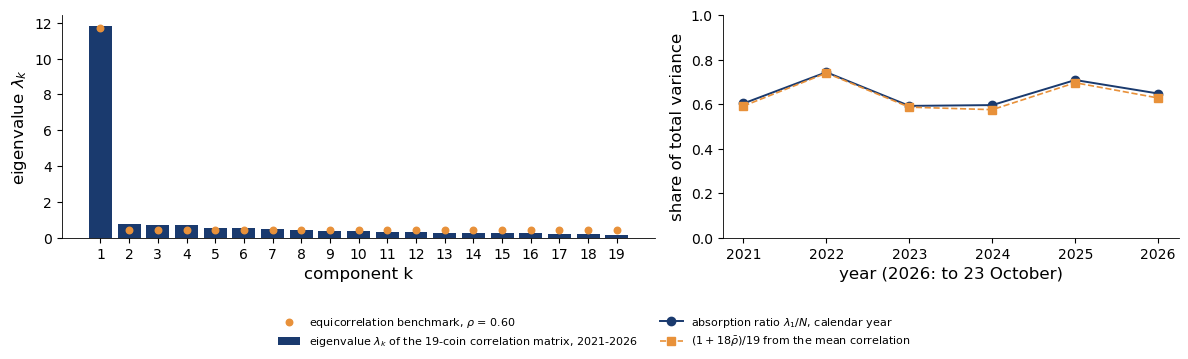

In [6]:
N = len(COINS)
iu = np.triu_indices(N, 1)
C = R.corr()
ev = np.linalg.eigvalsh(C.values)[::-1]
rbar = C.values[iu].mean()
print(f'lambda_1 = {ev[0]:.2f}, lambda_2 = {ev[1]:.2f}; eigenvalues above 1: {(ev > 1).sum()}; absorption ratio {ev[0] / N:.2f}')
print(f'Equicorrelation benchmark, rho = {rbar:.2f}: lambda_1 = {1 + (N - 1) * rbar:.2f}, the others {1 - rbar:.2f}')
yr = {}
for Y in range(2021, 2027):
    c = R.loc[str(Y)].corr().values
    yr[Y] = {'mean correlation': c[iu].mean(), 'absorption ratio': np.linalg.eigvalsh(c)[-1] / N, '(1 + 18 rho)/19': (1 + (N - 1) * c[iu].mean()) / N}
yr = pd.DataFrame(yr).T
print(yr.round(3).to_string())

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={'width_ratios': [1.3, 1]})
k = np.arange(1, N + 1)
ax[0].bar(k, ev, color=BLUE, label='eigenvalue $\\lambda_k$ of the 19-coin correlation matrix, 2021-2026')
ax[0].scatter(k, [1 + (N - 1) * rbar] + [1 - rbar] * (N - 1), color=BTC, s=22, zorder=5, label=f'equicorrelation benchmark, $\\rho$ = {rbar:.2f}')
ax[0].set_xticks(k); ax[0].set_xlabel('component k'); ax[0].set_ylabel('eigenvalue $\\lambda_k$')
ax[1].plot(yr.index, yr['absorption ratio'], color=BLUE, marker='o', lw=1.4, label='absorption ratio $\\lambda_1/N$, calendar year')
ax[1].plot(yr.index, yr['(1 + 18 rho)/19'], color=BTC, marker='s', lw=1.2, ls='--', label='$(1 + 18\\bar\\rho)/19$ from the mean correlation')
ax[1].set_ylim(0, 1); ax[1].set_xlabel('year (2026: to 23 October)'); ax[1].set_ylabel('share of total variance')
slide_fig(fig, 'ba_l6_eigen', 0.16, ncol=2)

**How to read it.** One eigenvalue dominates and all others are below 1: one common factor. The mean pairwise correlation alone predicts the
absorption ratio of each year closely.